In [1]:
%pip install pandas matplotlib plotly openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [6]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

# Load the original dataset
file_path = Path("HospitalOPD-noname.csv")

if not file_path.exists():
    raise FileNotFoundError(
        "Dataset not found. Place HospitalOPD-noname.csv "
        "in the same folder as this notebook."
    )

df = pd.read_csv(file_path, low_memory=False)

# Remove completely empty columns and clean column names
df = df.dropna(axis=1, how="all")
df.columns = df.columns.str.strip()

print("Dataset loaded successfully.")
print("Rows:", f"{len(df):,}")
print("Columns:", len(df.columns))

print("\nRequired timestamp columns:")
required_timestamps = [
    "appointment_start_datetime",
    "prescription_start_datetime",
    "lab_start_datetime",
    "imaging_start_datetime",
    "pharmacy_start_datetime"
]

for col in required_timestamps:
    print(f"{col}: {'Found' if col in df.columns else 'Not found'}")

Dataset loaded successfully.
Rows: 62,422
Columns: 24

Required timestamp columns:
appointment_start_datetime: Found
prescription_start_datetime: Found
lab_start_datetime: Found
imaging_start_datetime: Found
pharmacy_start_datetime: Found


##### Identify appointment IDs and prepare timestamps

In [7]:
# Identify the appointment ID column
appointment_candidates = [
    col for col in df.columns
    if col.lower().replace(" ", "_") in [
        "appointment_id",
        "appointmentid",
        "appointment_no",
        "appointment_number"
    ]
]

if not appointment_candidates:
    appointment_candidates = [
        col for col in df.columns
        if "appointment" in col.lower()
        and "id" in col.lower()
    ]

if not appointment_candidates:
    raise ValueError(
        "Appointment ID column not found. "
        "Check the column names from Step 2."
    )

appointment_col = appointment_candidates[0]

# Activity names and their timestamp columns
activity_columns = {
    "Appointment Started": "appointment_start_datetime",
    "Prescription Started": "prescription_start_datetime",
    "Lab Started": "lab_start_datetime",
    "Imaging Started": "imaging_start_datetime",
    "Pharmacy Started": "pharmacy_start_datetime"
}

# Keep activities whose timestamp columns exist
activity_columns = {
    activity: col
    for activity, col in activity_columns.items()
    if col in df.columns
}

if "Appointment Started" not in activity_columns:
    raise ValueError("Appointment start timestamp is missing.")

# Convert timestamps to datetime
for col in activity_columns.values():
    df[col] = pd.to_datetime(df[col], errors="coerce")

# Create a working copy for analysis
work = df[[appointment_col] + list(activity_columns.values())].copy()

# Remove rows without an appointment identifier
work = work.dropna(subset=[appointment_col])

print("Appointment ID column identified.")
print("Available activity types:", len(activity_columns))
print("Appointments represented in source rows:", f"{work[appointment_col].nunique():,}")

Appointment ID column identified.
Available activity types: 5
Appointments represented in source rows: 49,912


In [8]:
event_frames = []

for activity, timestamp_col in activity_columns.items():
    temp = work[[appointment_col, timestamp_col]].dropna().copy()

    temp = temp.rename(columns={
        appointment_col: "appointment_id",
        timestamp_col: "timestamp"
    })

    temp["activity"] = activity

    event_frames.append(
        temp[["appointment_id", "timestamp", "activity"]]
    )

event_log = pd.concat(event_frames, ignore_index=True)

# Remove exact duplicate events only.
# Do not remove repeated activities at different timestamps.
event_log = event_log.drop_duplicates(
    subset=["appointment_id", "timestamp", "activity"]
)

# Sort by appointment, timestamp, and activity name for reproducibility
event_log = event_log.sort_values(
    ["appointment_id", "timestamp", "activity"],
    kind="mergesort"
).reset_index(drop=True)

# Count the number of events per appointment
events_per_appointment = event_log.groupby("appointment_id").size()

print("Full event log created.")
print("Total events:", f"{len(event_log):,}")
print("Appointments with recorded events:", f"{event_log['appointment_id'].nunique():,}")
print("Activity types:", event_log["activity"].nunique())
print("Appointments with 1+ events:", f"{len(events_per_appointment):,}")

Full event log created.
Total events: 112,517
Appointments with recorded events: 49,912
Activity types: 5
Appointments with 1+ events: 49,912


In [9]:
# A. FULL EVENT FLOW: count consecutive activity transitions

event_log["next_activity"] = (
    event_log.groupby("appointment_id")["activity"].shift(-1)
)

transition_rows = event_log.dropna(
    subset=["next_activity"]
).copy()

transition_summary = (
    transition_rows
    .groupby(["activity", "next_activity"])
    .size()
    .reset_index(name="transition_count")
)

if not transition_summary.empty:
    transition_summary["percentage_of_transitions"] = (
        transition_summary["transition_count"]
        / transition_summary["transition_count"].sum()
        * 100
    ).round(2)

    transition_summary = transition_summary.sort_values(
        "transition_count", ascending=False
    ).reset_index(drop=True)


# B. TYPICAL PATHWAYS: create one sequence per appointment

appointment_sequences = (
    event_log.groupby("appointment_id", sort=False)["activity"]
    .agg(list)
)

# Convert each activity list into a readable sequence
pathway_strings = appointment_sequences.apply(
    lambda activities: " -> ".join(activities)
)

pathway_summary = (
    pathway_strings
    .value_counts()
    .rename_axis("pathway")
    .reset_index(name="appointment_count")
)

if not pathway_summary.empty:
    pathway_summary["percentage_of_appointments"] = (
        pathway_summary["appointment_count"]
        / appointment_sequences.shape[0]
        * 100
    ).round(2)

    pathway_summary = pathway_summary.sort_values(
        ["appointment_count", "pathway"],
        ascending=[False, True]
    ).reset_index(drop=True)


print("FULL EVENT FLOW")
print("Unique transition types:", len(transition_summary))
display(transition_summary.head(10))

print("\nMOST COMMON APPOINTMENT PATHWAYS")
print("Unique pathway patterns:", len(pathway_summary))
display(pathway_summary.head(10))

FULL EVENT FLOW
Unique transition types: 20


,activity,next_activity,transition_count,percentage_of_transitions
0,Appointment Started,Prescription Started,47939,76.57
1,Prescription Started,Lab Started,5296,8.46
2,Prescription Started,Imaging Started,2975,4.75
3,Imaging Started,Prescription Started,1664,2.66
4,Appointment Started,Imaging Started,1600,2.56
5,Imaging Started,Lab Started,614,0.98
6,Prescription Started,Prescription Started,543,0.87
7,Lab Started,Imaging Started,481,0.77
8,Lab Started,Prescription Started,385,0.61
9,Appointment Started,Lab Started,358,0.57



MOST COMMON APPOINTMENT PATHWAYS
Unique pathway patterns: 103


,pathway,appointment_count,percentage_of_appointments
0,Appointment Started -> Prescription Started,39203,78.54
1,Appointment Started -> Prescription Started ->...,4334,8.68
2,Appointment Started -> Prescription Started ->...,2217,4.44
3,Appointment Started -> Imaging Started -> Pres...,1216,2.44
4,Appointment Started -> Prescription Started ->...,555,1.11
5,Appointment Started -> Prescription Started ->...,430,0.86
6,Appointment Started -> Prescription Started ->...,396,0.79
7,Appointment Started -> Imaging Started -> Pres...,288,0.58
8,Appointment Started -> Lab Started -> Prescrip...,260,0.52
9,Imaging Started -> Appointment Started -> Pres...,222,0.44


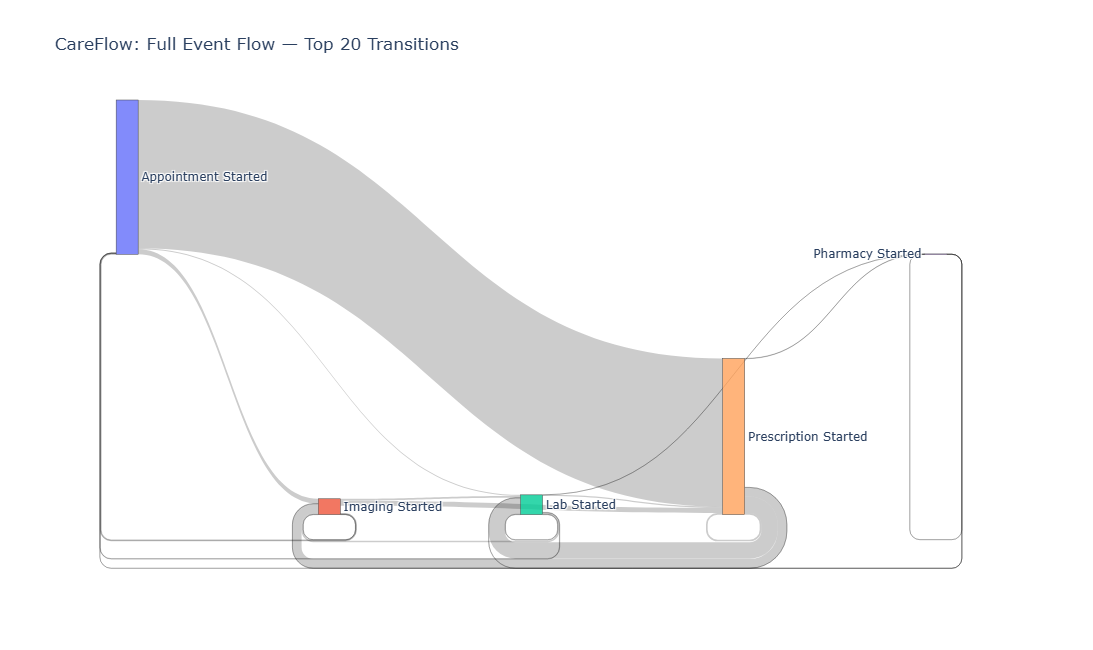

Saved: careflow_full_event_flow.html


In [10]:
# Select the most frequent transitions for the diagram
top_transitions = transition_summary.head(20).copy()

if top_transitions.empty:
    print("No transitions are available to visualize.")
else:
    activities = sorted(set(
        top_transitions["activity"].tolist()
        + top_transitions["next_activity"].tolist()
    ))

    activity_to_index = {
        activity: i for i, activity in enumerate(activities)
    }

    fig = go.Figure(data=[go.Sankey(
        arrangement="snap",
        node=dict(
            pad=25,
            thickness=22,
            label=activities,
            line=dict(width=0.5)
        ),
        link=dict(
            source=[
                activity_to_index[x]
                for x in top_transitions["activity"]
            ],
            target=[
                activity_to_index[x]
                for x in top_transitions["next_activity"]
            ],
            value=top_transitions["transition_count"].tolist(),
            customdata=top_transitions["percentage_of_transitions"].tolist(),
            hovertemplate=(
                "%{source.label} → %{target.label}"
                "<br>Transitions: %{value:,}"
                "<br>Share of all transitions: %{customdata:.2f}%"
                "<extra></extra>"
            )
        )
    )])

    fig.update_layout(
        title="CareFlow: Full Event Flow — Top 20 Transitions",
        font_size=12,
        height=650
    )

    fig.show()

    fig.write_html(
        "careflow_full_event_flow.html",
        include_plotlyjs=True
    )

    print("Saved: careflow_full_event_flow.html")

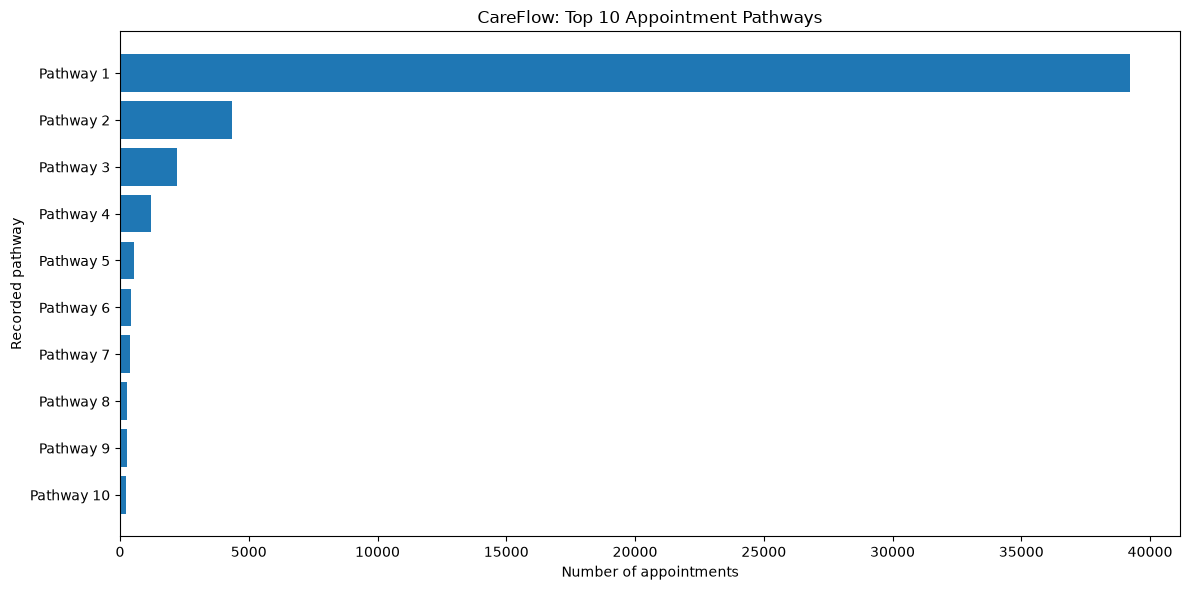


Pathway label reference:
Pathway 1: 39,203 appointments (78.54%)
  Appointment Started -> Prescription Started

Pathway 2: 4,334 appointments (8.68%)
  Appointment Started -> Prescription Started -> Lab Started

Pathway 3: 2,217 appointments (4.44%)
  Appointment Started -> Prescription Started -> Imaging Started

Pathway 4: 1,216 appointments (2.44%)
  Appointment Started -> Imaging Started -> Prescription Started

Pathway 5: 555 appointments (1.11%)
  Appointment Started -> Prescription Started -> Imaging Started -> Lab Started

Pathway 6: 430 appointments (0.86%)
  Appointment Started -> Prescription Started -> Prescription Started

Pathway 7: 396 appointments (0.79%)
  Appointment Started -> Prescription Started -> Lab Started -> Imaging Started

Pathway 8: 288 appointments (0.58%)
  Appointment Started -> Imaging Started -> Prescription Started -> Lab Started

Pathway 9: 260 appointments (0.52%)
  Appointment Started -> Lab Started -> Prescription Started

Pathway 10: 222 appoint

In [11]:
top_pathways = pathway_summary.head(10).copy()

if top_pathways.empty:
    print("No appointment pathways are available.")
else:
    top_pathways["pathway_label"] = [
        f"Pathway {i + 1}"
        for i in range(len(top_pathways))
    ]

    plt.figure(figsize=(12, 6))

    plt.barh(
        top_pathways["pathway_label"][::-1],
        top_pathways["appointment_count"][::-1]
    )

    plt.xlabel("Number of appointments")
    plt.ylabel("Recorded pathway")
    plt.title("CareFlow: Top 10 Appointment Pathways")
    plt.tight_layout()

    plt.savefig(
        "careflow_top_pathways.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("\nPathway label reference:")
    for _, row in top_pathways.iterrows():
        print(
            f"{row['pathway_label']}: "
            f"{row['appointment_count']:,} appointments "
            f"({row['percentage_of_appointments']:.2f}%)"
        )
        print("  " + row["pathway"])
        print()

    print("Saved: careflow_top_pathways.png")

In [12]:
comparison = pd.DataFrame([
    {
        "analysis_view": "Full event flow",
        "measure": "Distinct activity transitions",
        "result": len(transition_summary)
    },
    {
        "analysis_view": "Appointment pathways",
        "measure": "Distinct complete pathway patterns",
        "result": len(pathway_summary)
    },
    {
        "analysis_view": "Appointment pathways",
        "measure": "Appointments represented",
        "result": len(appointment_sequences)
    }
])

print("CareFlow pathway comparison")
display(comparison)

CareFlow pathway comparison


,analysis_view,measure,result
0,Full event flow,Distinct activity transitions,20
1,Appointment pathways,Distinct complete pathway patterns,103
2,Appointment pathways,Appointments represented,49912


In [13]:
output_excel = "careflow_pathway_intelligence_summary.xlsx"

# Keep only the top 20 pathways in the shared output
# This reduces unnecessary disclosure of rare pathway patterns.
top_20_pathways = pathway_summary.head(20).copy()

with pd.ExcelWriter(output_excel, engine="openpyxl") as writer:
    transition_summary.to_excel(
        writer,
        sheet_name="Transition Summary",
        index=False
    )

    top_20_pathways.to_excel(
        writer,
        sheet_name="Top 20 Pathways",
        index=False
    )

    comparison.to_excel(
        writer,
        sheet_name="Comparison Metrics",
        index=False
    )

print("Saved aggregate summary:", output_excel)

Saved aggregate summary: careflow_pathway_intelligence_summary.xlsx


In [14]:
report_file = "careflow_pathway_insights.txt"

with open(report_file, "w", encoding="utf-8") as file:
    file.write("CAREFLOW PATHWAY INTELLIGENCE — DAY 7\n")
    file.write("=" * 48 + "\n\n")

    file.write(
        f"Appointments represented: {len(appointment_sequences):,}\n"
    )
    file.write(f"Events analyzed: {len(event_log):,}\n")
    file.write(f"Activity types: {event_log['activity'].nunique()}\n")
    file.write(f"Distinct transition types: {len(transition_summary):,}\n")
    file.write(f"Distinct pathway patterns: {len(pathway_summary):,}\n\n")

    file.write("TOP 5 RECORDED TRANSITIONS\n")
    file.write("-" * 30 + "\n")

    if transition_summary.empty:
        file.write("No transitions were identified.\n")
    else:
        for _, row in transition_summary.head(5).iterrows():
            file.write(
                f"{row['activity']} -> {row['next_activity']}: "
                f"{row['transition_count']:,} transitions\n"
            )

    file.write("\nTOP 5 RECORDED PATHWAYS\n")
    file.write("-" * 30 + "\n")

    if pathway_summary.empty:
        file.write("No pathways were identified.\n")
    else:
        for _, row in pathway_summary.head(5).iterrows():
            file.write(
                f"{row['appointment_count']:,} appointments "
                f"({row['percentage_of_appointments']:.2f}%): "
                f"{row['pathway']}\n"
            )

    file.write("\nLIMITATIONS\n")
    file.write("-" * 30 + "\n")
    file.write(
        "Transitions are derived from recorded timestamps.\n"
        "Equal timestamps can make event ordering ambiguous.\n"
        "A frequent transition does not establish a clinical bottleneck.\n"
        "Recorded durations do not necessarily represent waiting time.\n"
        "Results describe the available data and do not prove causation.\n"
    )

print("Saved report:", report_file)

Saved report: careflow_pathway_insights.txt


In [16]:
expected_files = [
    "careflow_full_event_flow.html",
    "careflow_top_pathways.png",
    "careflow_pathway_intelligence_summary.xlsx",
    "careflow_pathway_insights.txt"
]

print("output check")
print("-" * 35)

for filename in expected_files:
    exists = Path(filename).exists()
    print(f"{filename}: {'Created' if exists else 'Missing'}")

output check
-----------------------------------
careflow_full_event_flow.html: Created
careflow_top_pathways.png: Created
careflow_pathway_intelligence_summary.xlsx: Created
careflow_pathway_insights.txt: Created
